# Feature Scaling
### Machine Learning — Data Preparation

---

## 1. What is Feature Scaling?

**Feature scaling** is the process of bringing all numerical columns in your dataset into the **same range or scale** before training a machine learning model.

> Think of it like this: if one column has values in the thousands and another has values 1–10, the model might wrongly think the bigger numbers are more important!

### Why do we need it?

Example: House price prediction dataset

| Column | Example Values | Scale |
|---|---|---|
| Square Feet | 7,000 – 25,000 | Thousands |
| Number of Rooms | 3 – 8 | Single digits |

Without scaling, the model gives more importance to **Square Feet** just because the numbers are bigger — even though **Number of Rooms** is equally important.

### Benefits of scaling
- **Removes bias** — model treats all features equally
- **Speeds up training** — math calculations are simpler with uniform ranges
- **Improves accuracy** — especially for distance-based models like KNN

In [21]:
# Import all required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [22]:
# Create a sample house dataset to work with throughout this notebook
data = {
    'square_feet': [7000, 10000, 12000, 15000, 18000, 20000, 22000, 25000],
    'num_rooms':   [3,    4,     4,     5,     5,     6,     7,     8    ],
    'age_years':   [25,   10,    5,     30,    15,    2,     8,     20   ]
}

df = pd.DataFrame(data)
print("Our sample dataset:")
df

Our sample dataset:


,square_feet,num_rooms,age_years
0,7000,3,25
1,10000,4,10
2,12000,4,5
3,15000,5,30
4,18000,5,15
5,20000,6,2
6,22000,7,8
7,25000,8,20


In [23]:
# See the huge difference in scale across columns
print("Column Statistics:")
df.describe().round(2)

Column Statistics:


,square_feet,num_rooms,age_years
count,8.00,8.00,8.00
mean,16125.00,5.25,14.38
std,6220.65,1.67,9.93
min,7000.00,3.00,2.00
25%,11500.00,4.00,7.25
50%,16500.00,5.00,12.50
75%,20500.00,6.25,21.25
max,25000.00,8.00,30.00


Notice how `square_feet` ranges from 7,000 to 25,000 while `num_rooms` only goes from 3 to 8. This scale difference is exactly what we need to fix!

---
## 2. Types of Scaling

There are two main techniques for scaling numerical data:

---

### Type 1: Standardization (Z-score Scaling)

Transforms data using the column's **mean** and **standard deviation**.

$$z = \frac{x - \mu}{\sigma}$$

Where:
- $x$ = original value
- $\mu$ = mean of the column
- $\sigma$ = standard deviation of the column

**Steps:**
1. Calculate the mean — sum of all values divided by count
2. Calculate the standard deviation — how spread out values are around the mean
3. Apply the formula to each value in the column

**Result:** Most values will fall between **-3 and +3**. The mean becomes exactly **0**.

In [24]:
# -----------------------------------------------
# Manual Z-score calculation (to understand the math)
# -----------------------------------------------

col = df['square_feet']

mean_val = col.mean()
std_val  = col.std()

print(f"Column : square_feet")
print(f"Mean   : {mean_val:.2f}")
print(f"Std Dev: {std_val:.2f}")
print()

# Apply formula manually
manual_scaled = (col - mean_val) / std_val
print("Manually standardized values:")
print(manual_scaled.round(4).tolist())

Column : square_feet
Mean   : 16125.00
Std Dev: 6220.65

Manually standardized values:
[-1.4669, -0.9846, -0.6631, -0.1808, 0.3014, 0.6229, 0.9444, 1.4267]


In [25]:
# -----------------------------------------------
# Standardization using sklearn — StandardScaler
# -----------------------------------------------

# Step 1: Initialize the scaler
ss = StandardScaler()

# Step 2: Fit and transform the entire DataFrame
df_standard = ss.fit_transform(df)

# Step 3: Convert back to a readable DataFrame
df_standard = pd.DataFrame(df_standard, columns=df.columns)

print("Standardized DataFrame:")
df_standard.round(4)

Standardized DataFrame:


,square_feet,num_rooms,age_years
0,-1.5682,-1.4412,1.1442
1,-1.0526,-0.8006,-0.4711
2,-0.7089,-0.8006,-1.0096
3,-0.1933,-0.1601,1.6826
4,0.3222,-0.1601,0.0673
5,0.6659,0.4804,-1.3326
6,1.0096,1.1209,-0.6865
7,1.5252,1.7614,0.6057


In [26]:
# Verify: mean should be ~0, std should be ~1 for every column
print("Mean of each column (should be ~0):")
print(df_standard.mean().round(10))

print("\nStd Dev of each column (should be ~1):")
print(df_standard.std().round(4))

Mean of each column (should be ~0):
square_feet    0.0
num_rooms      0.0
age_years      0.0
dtype: float64

Std Dev of each column (should be ~1):
square_feet    1.069
num_rooms      1.069
age_years      1.069
dtype: float64


---
### Type 2: Min-Max Scaling

Transforms data using the **minimum** and **maximum** values of the column. Everything gets squeezed into the range **[0, 1]**.

$$x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

**Example calculation:**
```
Column values: 2000, 7000, 8000, 12000, 25000
min = 2,000   |   max = 25,000

For x = 7,000:   (7000 - 2000) / (25000 - 2000) = 5000 / 23000 = 0.217
```

**Result:** The minimum value becomes **0**, the maximum becomes **1**, everything else lands in between.

In [27]:
# -----------------------------------------------
# Manual Min-Max calculation (to understand the math)
# -----------------------------------------------

col = df['square_feet']

min_val = col.min()
max_val = col.max()

print(f"Column : square_feet")
print(f"Min    : {min_val}")
print(f"Max    : {max_val}")
print()

# Apply formula manually
manual_minmax = (col - min_val) / (max_val - min_val)
print("Manually Min-Max scaled values:")
print(manual_minmax.round(4).tolist())

Column : square_feet
Min    : 7000
Max    : 25000

Manually Min-Max scaled values:
[0.0, 0.1667, 0.2778, 0.4444, 0.6111, 0.7222, 0.8333, 1.0]


In [28]:
# -----------------------------------------------
# Min-Max Scaling using sklearn — MinMaxScaler
# -----------------------------------------------

# Step 1: Initialize the scaler
mm = MinMaxScaler()

# Step 2: Fit and transform the entire DataFrame
df_minmax = mm.fit_transform(df)

# Step 3: Convert back to a readable DataFrame
df_minmax = pd.DataFrame(df_minmax, columns=df.columns)

print("Min-Max Scaled DataFrame:")
df_minmax.round(4)

Min-Max Scaled DataFrame:


,square_feet,num_rooms,age_years
0,0.0000,0.0,0.8214
1,0.1667,0.2,0.2857
2,0.2778,0.2,0.1071
3,0.4444,0.4,1.0000
4,0.6111,0.4,0.4643
5,0.7222,0.6,0.0000
6,0.8333,0.8,0.2143
7,1.0000,1.0,0.6429


In [29]:
# Verify: min should be 0, max should be 1 for every column
print("Min of each column (should be 0):")
print(df_minmax.min())

print("\nMax of each column (should be 1):")
print(df_minmax.max())

Min of each column (should be 0):
square_feet    0.0
num_rooms      0.0
age_years      0.0
dtype: float64

Max of each column (should be 1):
square_feet    1.0
num_rooms      1.0
age_years      1.0
dtype: float64


---
## 3. Standardization vs Min-Max — Quick Comparison

| | Standardization | Min-Max Scaling |
|---|---|---|
| **Output range** | ~-3 to +3 | 0 to 1 |
| **Formula uses** | Mean & standard deviation | Min & max values |
| **Speed** | Slightly slower | Faster |
| **sklearn class** | `StandardScaler` | `MinMaxScaler` |
| **Best when** | Data has outliers / normal distribution | Bounded range needed |

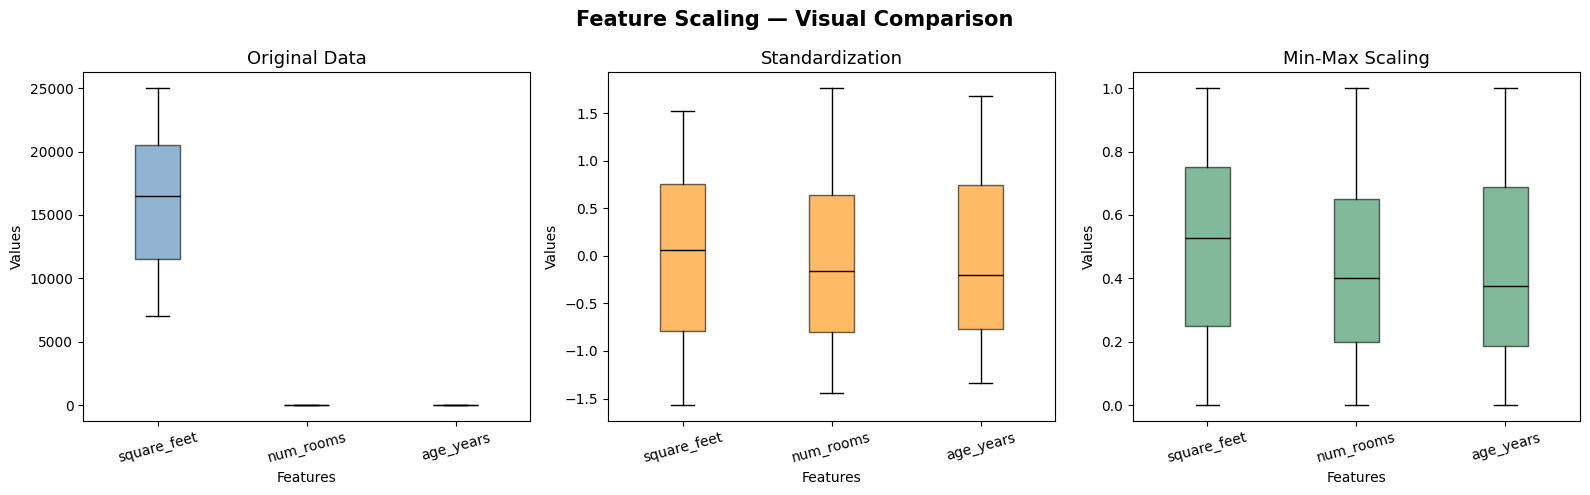

In [30]:
# -----------------------------------------------
# Visual comparison: Original vs Standardized vs Min-Max
# -----------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Feature Scaling — Visual Comparison', fontsize=15, fontweight='bold')

datasets = [
    (df,           'Original Data',       'steelblue'),
    (df_standard,  'Standardization',     'darkorange'),
    (df_minmax,    'Min-Max Scaling',     'seagreen'),
]

for ax, (data, title, color) in zip(axes, datasets):
    # Use matplotlib's boxplot directly (pandas' DataFrame.boxplot mishandles `color`)
    ax.boxplot(
        data.values,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.6),
        medianprops=dict(color='black'),
    )
    ax.set_xticks(range(1, len(data.columns) + 1))
    ax.set_xticklabels(data.columns)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('Features')
    ax.set_ylabel('Values')
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [31]:
# -----------------------------------------------
# Side-by-side value comparison for square_feet column
# -----------------------------------------------

comparison = pd.DataFrame({
    'Original':       df['square_feet'],
    'Standardized':   df_standard['square_feet'].round(4),
    'Min-Max Scaled': df_minmax['square_feet'].round(4)
})

print("Comparison for 'square_feet' column:")
comparison

Comparison for 'square_feet' column:


,Original,Standardized,Min-Max Scaled
0,7000,-1.5682,0.0000
1,10000,-1.0526,0.1667
2,12000,-0.7089,0.2778
3,15000,-0.1933,0.4444
4,18000,0.3222,0.6111
5,20000,0.6659,0.7222
6,22000,1.0096,0.8333
7,25000,1.5252,1.0000


---
## 4. Key Takeaway

> **Scaling does NOT change the meaning of your data** — it just makes all columns speak the same language so the model can learn fairly and efficiently.

**Remember:**
- Always scale **only numerical columns**
- Scaling is done **before model training**
- Both techniques are available in `sklearn.preprocessing`

| Situation | Use |
|---|---|
| Data has outliers or follows normal distribution | `StandardScaler` |
| You need values strictly between 0 and 1 | `MinMaxScaler` |
| Neural networks / image data | `MinMaxScaler` |
| Most general ML models | Either works, `StandardScaler` is safer |